# Python SDK：真实 NMR 推理

本教程把数据记录与 NMRNet 模型接口连接起来。你将查看分子记录、配置模型环境、预测逐原子位移，并与实验峰位置比较。

In [1]:
import json, os, sys, io, tempfile
from pathlib import Path
from IPython.display import display, SVG
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'documentation/assets').is_dir())
from openmolspec.dataset import MolecularSpectra, list_datasets
print('Registered datasets:', [c['name'] for c in list_datasets()])

Registered datasets: ['transpeaknet_hsqc_test', 'opendatalab_nmr', 'nmrspec_test', 'patent_test_10k', 'nmrexp_exp_10k', 'nmrgym_test', 'openspec_test', 'massspecgym_test', 'massspecgym_1_5', 'opendatalab_nmr_prepared', 'opendatalab_ir', 'opendatalab_19f', 'opendatalab_31p', 'opendatalab_ms', 'opendatalab_11b', 'opendatalab_raman', 'opendatalab_29si']


## 1. 读取分子谱

附带的 NMRSpec 示例包含结构、分子式、谱记录和参考峰数组。先查看第一条，了解预测与评测所使用的字段。

In [2]:
data = MolecularSpectra.from_jsonl(splits={'test': root / 'documentation/assets/sdk-nmr-test-examples.jsonl'}, name='documented_nmrspec_examples', domain='experimental')
rows = data['test'].head(3)
print(json.dumps(rows[0], indent=2, ensure_ascii=False))
print('Split roles:', list(data.get_split()))

{
  "inchi": "InChI=1S/C22H28/c1-18(10-8-9-13-19-11-6-5-7-12-19)20-14-16-21(17-15-20)22(2,3)4/h5-7,11-12,14-17H,1,8-10,13H2,2-4H3",
  "smiles": "C=C(CCCCc1ccccc1)c1ccc(C(C)(C)C)cc1",
  "formula": "C22H28",
  "h_nmr": [
    {
      "type": "1H NMR",
      "chemical_shift": "7.34 (s, 4H), 7.265 (m, 2H), 7.165 (m, 3H), 5.26 (d, J=1.6 Hz, 1H), 5.01 (t, J=1.4 Hz, 1H), 2.61 (t, J=7.8 Hz, 2H), 2.53 (t, J=7.6 Hz, 2H), 1.665 (m, 2H), 1.52 (d, J=7.7 Hz, 2H), 1.33 (s, 9H)"
    }
  ],
  "c_nmr": [
    {
      "type": "13C NMR",
      "chemical_shift": "150.22, 148.03, 142.68, 138.28, 128.36, 128.22, 125.68, 125.58, 125.12, 111.51, 35.72, 35.03, 34.46, 31.32, 31.11, 27.93"
    }
  ],
  "modality_mask": [
    1,
    1
  ],
  "_openmolspec": {
    "dataset": "documented_nmrspec_examples",
    "domain": "experimental",
    "split": "test",
    "record_locator": "sdk-nmr-test-examples.jsonl:1",
    "modalities": [
      "13C",
      "1H"
    ]
  },
  "reference_peaks_ppm": [
    150.22,
    148.03,
   

## 2. 配置并调用 NMRNet

`OPENMOLSPEC_MODELS_ROOT` 指向包含 `nmrnet/` 的目录，`OPENMOLSPEC_NMR_PYTHON` 指向安装了模型依赖的解释器。下面生成构象并预测碳位移，每个预测值附有 0 起始原子编号。

In [3]:
from openmolspec.model import NMRNet
model_root = os.environ.get('OPENMOLSPEC_MODELS_ROOT')
if not model_root:
    raise RuntimeError('Set OPENMOLSPEC_MODELS_ROOT to the directory containing nmrnet/; see Python SDK guide')
model = NMRNet.from_pretrained(model_root, nucleus='13C', python=os.environ.get('OPENMOLSPEC_NMR_PYTHON', sys.executable))
result = model.predict(rows[0]['smiles'])
print(json.dumps(result['records'], indent=2))
print('Checkpoint SHA-256:', result['provenance']['checkpoint_sha256'])
assert result['training_performed'] is False

[
  {
    "smiles": "C=C(CCCCc1ccccc1)c1ccc(C(C)(C)C)cc1",
    "nucleus": "13C",
    "atom_indices": [
      0,
      1,
      2,
      3,
      4,
      5,
      6,
      7,
      8,
      9,
      10,
      11,
      12,
      13,
      14,
      15,
      16,
      17,
      18,
      19,
      20,
      21
    ],
    "prediction_ppm": [
      111.92984008789062,
      148.56301879882812,
      34.59314727783203,
      27.106813430786133,
      30.951845169067383,
      35.74639129638672,
      142.5129852294922,
      128.4691619873047,
      128.4962158203125,
      126.21155548095703,
      128.5539093017578,
      128.6055450439453,
      139.7798614501953,
      126.32313537597656,
      125.47481536865234,
      150.09881591796875,
      34.164398193359375,
      31.407787322998047,
      31.511058807373047,
      31.552867889404297,
      125.4945297241211,
      126.05933380126953
    ]
  }
]
Checkpoint SHA-256: 0efb06c233a6e851629f695e516d94209963fb60df39194a5dbb20bd3cb9db7

## 3. 评估并绘制预测

`evaluate_nmr` 将预测位移与实验峰匹配，给出残差和覆盖率。图中参考与预测使用同一 ppm 轴，可直接观察缺失峰、额外峰和位移差。

{
  "matched_peak_mae_ppm": 0.360868186950682,
  "matched_peak_rmse_ppm": 0.5066505398060095,
  "peak_count_mae": 6.0,
  "matched_fraction": 0.7272727272727273,
  "examples": 1,
  "scored_examples": 1,
  "aggregation": "equal_weight_per_molecule",
  "assignment": "minimum_absolute_error_without_atom_labels"
}


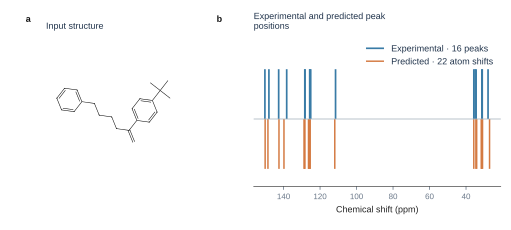

In [4]:
from openmolspec.benchmark import evaluate_nmr
reference = rows[0]['reference_peaks_ppm']
print(json.dumps(evaluate_nmr(result, [reference]), indent=2))
import matplotlib.pyplot as plt
sys.path.insert(0, str(root / 'scripts'))
from documentation_figures import render_task
figure_evidence = {'examples': [{'input': {'smiles': rows[0]['smiles']}}], 'plot': {'kind': 'nmr_peaks', 'smiles': rows[0]['smiles'], 'reference_ppm': reference, 'prediction_ppm': result['records'][0]['prediction_ppm'], 'label': 'Actual SDK inference; first documented NMRSpec molecule'}}
fig = render_task('nmr.forward.13C', figure_evidence)
image = io.StringIO()
fig.savefig(image, format='svg', metadata={'Date': None})
display(SVG(image.getvalue()))
plt.close(fig)

[Python SDK guide](../api.md)


## 参考文献

- Xu, F., Guo, W., Wang, F., Yao, L., Wang, H., Tang, F., Gao, Z., Zhang, L., E, W., Tian, Z.-Q., et al. Toward a unified benchmark and framework for deep learning-based prediction of nuclear magnetic resonance chemical shifts. Nature Computational Science 5, 292–300 (2025). doi:10.1038/s43588-025-00783-z. [Source](https://doi.org/10.1038/s43588-025-00783-z)
- Yang, L., Yang, Z., Xie, J., Wang, Y., Gao, B., Fu, T., Wei, X., Sun, J., Wu, J., He, C., Li, Y. & Gu, Q. NMRTrans: Structure Elucidation from Experimental NMR Spectra via Set Transformers. arXiv:2602.10158 (2026). [Source](https://arxiv.org/abs/2602.10158)
